In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import plotly.graph_objects as go
from google.colab import drive
from numpy import loadtxt, diff, mean, append, sort
from scipy.signal import find_peaks, peak_widths
from google.colab import drive
from pylab import plot, show, grid,legend, title, text, annotate
from random import random, randint
from scipy.interpolate import griddata
!pip install -U kaleido
# Montar Google Drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.3/66.3 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.3/52.3 kB 4.5 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:


dados3D = []
dadoss = []

def analise(
    url, temperatura, tensao,
    altura_pico=0.5, altura_vale=5, distancia_pico=4.5,
    limite_inf_pico=0.5, limite_sup_pico=None,
    limite_inf_vale=0.5, limite_sup_vale=None,
    plot=True, labels=True
):
    """
    Lê os dados de um arquivo, detecta picos e vales, calcula diferenças
    e incertezas, e retorna tudo.
    """
    # Leitura do arquivo
    df = pd.read_csv(
        url, sep='\\s+',
        converters={0: lambda x: float(x.replace(',', '.')),
                    1: lambda x: float(x.replace(',', '.'))},
        names=['tensao', 'corrente'], skiprows=5, encoding="utf-8"
    )

    df = df[:-1]  # remove última linha "ruim"
    x = df['tensao'].values
    y = df['corrente'].values

    # Função para cortar intervalo
    def inifim(lim_inferior, lim_superior):
        lista = np.array(df["tensao"])
        # início
        for inicio in range(len(lista)):
            if lista[inicio] >= lim_inferior:
                break
        # fim
        fim = len(lista)-1
        if lim_superior is not None:
            for fim in range(len(lista)):
                if lista[fim] >= lim_superior:
                    break
        return inicio, fim

    # --- Seleção para picos ---
    inicio_p, fim_p = inifim(limite_inf_pico, limite_sup_pico)
    selecao_x_p = x[inicio_p:fim_p]
    selecao_y_p = y[inicio_p:fim_p]

    todos_picos, _ = find_peaks(selecao_y_p, height=altura_pico, distance=distancia_pico)
    valores_picos = selecao_x_p[todos_picos]

    # Incerteza dos picos (largura à meia altura / 2)
    if len(todos_picos) > 0:
        results_half = peak_widths(selecao_y_p, todos_picos, rel_height=0.5)
        larguras_em_tensao = results_half[0] * np.mean(np.diff(selecao_x_p))
        incerteza_picos = larguras_em_tensao / 2
    else:
        incerteza_picos = np.array([])

    # --- Seleção para vales ---
    inicio_v, fim_v = inifim(limite_inf_vale, limite_sup_vale)
    selecao_x_v = x[inicio_v:fim_v]
    selecao_y_v = y[inicio_v:fim_v]

    todos_vales, _ = find_peaks(-selecao_y_v, height=-altura_vale, distance=distancia_pico)
    valores_vales = selecao_x_v[todos_vales]

    # Incerteza dos vales (largura à meia altura / 2)
    if len(todos_vales) > 0:
        results_half_v = peak_widths(-selecao_y_v, todos_vales, rel_height=0.5)
        larguras_vales = results_half_v[0] * np.mean(np.diff(selecao_x_v))
        incerteza_vales = larguras_vales / 2
    else:
        incerteza_vales = np.array([])

    # Armazenar dados para gráficos sobrepostos
    dadoss.append({
        "temperatura": temperatura,
        "tensao": tensao,
        "x": x,
        "y": y,
        "picos_x": valores_picos,
        "picos_y": selecao_y_p[todos_picos],
        "incerteza_picos": incerteza_picos,
        "vales_x": valores_vales,
        "vales_y": selecao_y_v[todos_vales],
        "incerteza_vales": incerteza_vales
    })
    dados3D.append((temperatura, tensao, df.copy()))

    # Plotagem opcional
    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(x, y, color='blue', label="Curva experimental")
        plt.errorbar(valores_picos, selecao_y_p[todos_picos], xerr=incerteza_picos, fmt='*', color='red', markersize=8, label='Picos ± incerteza')
        plt.errorbar(valores_vales, selecao_y_v[todos_vales], xerr=incerteza_vales, fmt='o', color='green', markersize=6, label='Vales ± incerteza')
        plt.title(f"Exp. Franck-Hertz Temp: {temperatura}°C Tensão: {tensao}V")
        plt.xlabel("Tensão (V)")
        plt.ylabel("Corrente (A)")
        plt.grid(True, alpha=0.5)
        plt.legend()
        plt.show()

    # --- Diferenças entre picos e vales ---
    picos_dif = []
    for i in range(len(valores_picos)-1):
        diferenca = valores_picos[i+1] - valores_picos[i]
        if labels:
            print(f"A diferença entre os picos {i+2} e {i+1} é de {diferenca:.2f} V")
        picos_dif.append(diferenca)

    vales_dif = []
    for i in range(len(valores_vales)-1):
        diferenca = valores_vales[i+1] - valores_vales[i]
        if labels:
            print(f"A diferença entre os vales {i+2} e {i+1} é de {diferenca:.2f} V")
        vales_dif.append(diferenca)

    # Retorna picos, vales e suas incertezas
    return picos_dif, vales_dif, incerteza_picos, incerteza_vales

In [3]:
def grafico3D(tipo="temperatura", sep=True, num_pontos=100):
    """ Gera gráfico 3D interativo com Plotly """
    if sep:
      fig = go.Figure()

      for temp, U, df in dados3D:
          V = df['tensao'].values
          I = df['corrente'].values

          if tipo == "temperatura":
              eixoY = np.full_like(V, temp)
              y_label = "Temperatura (°C)"
          elif tipo == "retardo":
              eixoY = np.full_like(V, U)
              y_label = "Tensão de Retardo (V)"
          else:
              raise ValueError("tipo deve ser 'temperatura' ou 'retardo'")

          fig.add_trace(go.Scatter3d(
              x=V, y=eixoY, z=I,
              mode='lines',
              name=f"T={temp}°C, U={U}V",
              line=dict(width=4)
          ))


    else:
      X_all = []
      Y_all = []
      Z_all = []

      for temp, U, df in dados3D:
          cond = temp if tipo == "temperatura" else U
          V = df['tensao'].values
          I = df['corrente'].values
          X_all.extend(V)
          Y_all.extend([cond]*len(V))
          Z_all.extend(I)

      X_all = np.array(X_all)
      Y_all = np.array(Y_all)
      Z_all = np.array(Z_all)

      # --- Criar grade para interpolação ---
      xi = np.linspace(X_all.min(), X_all.max(), num_pontos)
      yi = np.linspace(Y_all.min(), Y_all.max(), num_pontos)
      XI, YI = np.meshgrid(xi, yi)

      # --- Interpolação ---
      ZI = griddata((X_all, Y_all), Z_all, (XI, YI), method='cubic')

      # --- Plotagem ---
      if tipo == "temperatura":
          y_label = "Temperatura (°C)"
      else:
          y_label = "Tensão de Retardo (V)"

      fig = go.Figure(data=[go.Surface(x=XI, y=YI, z=ZI, colorscale='Viridis')])

    fig.update_layout(
        width=1400,
      height=1000,
      scene=dict(
      aspectmode='manual',
      aspectratio=dict(x=1.5, y=1, z=0.7),
            xaxis_title="Tensão de Aceleração (V)",
            yaxis_title=y_label,
            zaxis_title="Corrente (A)"
        ),
        title="Corrente × Tensão × Temperatura - 2V"
    )

    fig.show()
    fig.write_html("/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/my_3DgraphMesmaTensao.html")



def analise_spectral(url):
    def wavelength_to_rgb(wavelength, gamma=0.8):
        ''' taken from http://www.noah.org/wiki/Wavelength_to_RGB_in_Python
        This converts a given wavelength of light to an
        approximate RGB color value. The wavelength must be given
        in nanometers in the range from 380 nm through 750 nm
        (789 THz through 400 THz).

        Based on code by Dan Bruton
        http://www.physics.sfasu.edu/astro/color/spectra.html
        Additionally alpha value set to 0.5 outside range
        '''
        wavelength = float(wavelength)
        if wavelength >= 380 and wavelength <= 750:
            A = 1.
        else:
            A=0.5
        if wavelength < 380:
            wavelength = 380.
        if wavelength >750:
            wavelength = 750.
        if wavelength >= 380 and wavelength <= 440:
            attenuation = 0.3 + 0.7 * (wavelength - 380) / (440 - 380)
            R = ((-(wavelength - 440) / (440 - 380)) * attenuation) ** gamma
            G = 0.0
            B = (1.0 * attenuation) ** gamma
        elif wavelength >= 440 and wavelength <= 490:
            R = 0.0
            G = ((wavelength - 440) / (490 - 440)) ** gamma
            B = 1.0
        elif wavelength >= 490 and wavelength <= 510:
            R = 0.0
            G = 1.0
            B = (-(wavelength - 510) / (510 - 490)) ** gamma
        elif wavelength >= 510 and wavelength <= 580:
            R = ((wavelength - 510) / (580 - 510)) ** gamma
            G = 1.0
            B = 0.0
        elif wavelength >= 580 and wavelength <= 645:
            R = 1.0
            G = (-(wavelength - 645) / (645 - 580)) ** gamma
            B = 0.0
        elif wavelength >= 645 and wavelength <= 750:
            attenuation = 0.3 + 0.7 * (750 - wavelength) / (750 - 645)
            R = (1.0 * attenuation) ** gamma
            G = 0.0
            B = 0.0
        else:
            R = 0.0
            G = 0.0
            B = 0.0
        return (R,G,B,A)

    # Leitura do arquivo usando pandas
    df = pd.read_csv(url, delim_whitespace=True,
                    converters={0: lambda x: float(x.replace(',', '.')),
                                1: lambda x: float(x.replace(',', '.'))},
                    names=['Comprimento', 'Intensidade'])

    x = df['Comprimento'].values
    y = df['Intensidade'].values

    # Detecta picos principais com altura mínima
    todos_picos, _ = find_peaks(y, height=1000, prominence=400)

    valores_picos = x[todos_picos]
    peaks_filtrados = [p for p in todos_picos if 350 <= x[p] <= 700]
    print(f'Os valores dos picos são: {valores_picos.round(2)}')

    # Plotagem
    plt.figure(figsize=(10.29, 8.01))
    plt.plot(x, y, color='black')

    # Gerar cores aleatórias com NumPy
    cores_aleatorias = [f'#{c:06x}' for c in np.random.randint(0, 0xFFFFFF + 1, size=len(todos_picos))]

    cores_aleatorias =[
        "#7F00FF",  # 364.4 nm - UV/violeta (representação)
        "#550082",  # 404.32 nm - violeta
        "#1D00F5",  # 435.74 nm - azul-violeta
        "#00FF7F",  # 512.1 nm - verde-ciano
        "#33FF33",  # 533.94 nm - verde
        "#96FF00",  # 545.83 nm - verde intenso
        "#F6FF00",  # 576.73 nm - amarelo
        "#FFEE00",  # 578.8 nm - amarelo (segunda linha)
    ]

    labels_hg = [
    r"$6^3D \rightarrow 6^3P_2$",  # 364.4 nm
    r"$7^3S \rightarrow 6^3P_0$",  # 404.32 nm
    r"$7^3S \rightarrow 6^3P_1$",  # 435.74 nm
    r"Pico referente a radiação do corpo negro",   # 512.1 nm
    r"Ruido ?",  # 533.94 nm
    r"$7^3S \rightarrow 6^3P_1$",  # 545.83 nm
    r"$6^3D \rightarrow 6^1P_2$",  # 576.73 nm
    r"$6^3D \rightarrow 6^1P_2$",  # 578.8 nm
]

    # Anotar os picos no gráfico
    for i, pico in enumerate(peaks_filtrados):
        cor = cores_aleatorias[i]
        label = labels_hg[i % len(labels_hg)]
        plt.plot(x[pico], y[pico], '*', markersize=8, color=cor, markeredgecolor='black',label=label)

        # Alternância entre esquerda e direita
        x_offset = 50 if i % 2 == 0 else 50
        y_offset = 0

        plt.annotate(f'{x[pico]:.2f}',
                    xy=(x[pico], y[pico]),
                    xytext=(x_offset, y_offset),
                    textcoords='offset points',
                    ha='center',
                    arrowprops=dict(arrowstyle='->', color=cor, lw=1, alpha=0.5),
                    bbox=dict(boxstyle='round,pad=0.3', facecolor=cor, alpha=0.6),
                    fontsize=10.5)

    #######Espectro sob a curva########
    step = max(1, len(x) // 500)  # Ajusta o passo baseado no número de pontos
    for i in range(0, len(x) - 1, step):
        if 380 <= x[i] <= 780:
            lambda_medio = (x[i] + x[i+1]) / 2
            rgb = wavelength_to_rgb(lambda_medio)

            plt.fill_between([x[i], x[min(i+step, len(x)-1)]],
                            [y[i], y[min(i+step, len(x)-1)]],
                            color=rgb, alpha=0.6)

    plt.title("Espectroscopia do Experimento de Franck Hertz",fontsize=18)
    plt.xlabel("Comprimento de Onda (nm)",fontsize=20)
    plt.ylabel("Intensidade",fontsize=20)
    plt.legend(fontsize=12)
    plt.tick_params(labelsize=20)
    plt.tight_layout()
    plt.xlim(350,620)
    plt.show()

    # Cálculo de Largura a Meia Altura (FWHM) e incertezas
    results = peak_widths(y, todos_picos, rel_height=0.5)

    for i, idx in enumerate(todos_picos):
        centro = x[idx]
        largura = results[0][i] * (x[1] - x[0])  # Convertendo índice para eixo x
        erro = largura / (2 * np.sqrt(6))       # Estimativa da incerteza

        print(f"Pico em x = {centro:.2f} ± {erro:.2f} (FWHM = {largura:.2f})")

In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_0V_161,2.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_1V_160,5.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_2V_158,7.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_3V_160,5.txt'

arquivos = [
    (url1, 160, 0),
    (url2, 160, 1),
    (url3, 160, 2),
    (url4, 160, 3)
]

plt.figure(figsize=(11,8))
cores = ['blue', 'red', 'green', 'purple']

for i, (url, temp, tensao) in enumerate(arquivos):
    picos, vales = analise(url, temp, tensao, plot=False, labels=False)
    dados = dadoss[-1]

    cor = cores[i % len(cores)]
    plt.plot(dados["x"], dados["y"], color=cor, label=f'Temperatura {temp}°C Tensao {tensao}V')
    plt.plot(dados["picos_x"], dados["picos_y"], '*', color='red', markersize=8)
    plt.plot(dados["vales_x"], dados["vales_y"], 'o', color='green', markersize=6)

plt.title("Exp. Franck-Hertz - Temperatura 160°C")
plt.xlabel("Tensão (V)")
plt.ylabel("Corrente (A)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_2V_158,7.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_2V_168,0.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_2V_182,0.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_2V_190,02.txt'

arquivos = [
    (url1, 160, 2),
    (url2, 170, 2),
    (url3, 180, 2),
    (url4, 190, 2)
]

plt.figure(figsize=(13,8))
cores = ['blue', 'red', 'green', 'purple']

for i, (url, temp, tensao) in enumerate(arquivos):
    picos, vales = analise(url, temp, tensao, plot=False, labels=False)
    dados = dadoss[-1]

    cor = cores[i % len(cores)]
    plt.plot(dados["x"], dados["y"], color=cor, label=f'Temperatura {temp}°C Tensao {tensao}V')
    plt.plot(dados["picos_x"], dados["picos_y"], '*', color='red', markersize=8)
    plt.plot(dados["vales_x"], dados["vales_y"], 'o', color='green', markersize=6)

plt.title("Exp. Franck-Hertz - Tensão 2V")
plt.xlabel("Tensão (V)")
plt.ylabel("Corrente (A)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

dados3D = []
analise(url1, 160, 2,plot=False)
analise(url2, 170, 2,plot=False)
analise(url3, 180, 2,plot=False)
analise(url4, 190, 2,plot=False)
grafico3D()


In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_0V_161,2.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_0V_175,7.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_0V_178.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_0A_190,0.txt'

arquivos = [
    (url1, 160, 0),
    (url2, 170, 0),
    (url3, 180, 0),
    (url4, 190, 0)
]

plt.figure(figsize=(12,6))
cores = ['blue', 'red', 'green', 'purple']

for i, (url, temp, tensao) in enumerate(arquivos):
    picos, vales = analise(url, temp, tensao, plot=False, labels=False)
    dados = dados3D[-1]

    cor = cores[i % len(cores)]
    plt.plot(dados["x"], dados["y"], color=cor, label=f'Temperatura {temp}°C Tensao {tensao}V')
    plt.plot(dados["picos_x"], dados["picos_y"], '*', color='red', markersize=8)
    plt.plot(dados["vales_x"], dados["vales_y"], 'o', color='green', markersize=6)

plt.title("Exp. Franck-Hertz - Tensão 0V")
plt.xlabel("Tensão (V)")
plt.ylabel("Corrente (A)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()



In [ ]:
urlspectra1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/Franck_Hertz_Spectra.txt'
urlspectra2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/Franck_Hertz_Spectra2.txt'

analise_spectral(urlspectra1)
analise_spectral(urlspectra2)

In [ ]:
# Caminho para o arquivo

url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_0V_161,2.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_1V_160,5.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_2V_158,7.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_3V_160,5.txt'

dados3D = []
analise(url1, 160, 0)
analise(url2, 160, 1,limite_inf_vale=5)
analise(url3, 160, 2)
analise(url4, 160, 3,limite_inf_vale=5)

grafico3D("retardo")

In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_0V_175,7.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_1V_170,2.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_2V_168,0.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_3V_170,4.txt'


analise(url1, 170, 0,limite_inf_vale=5)
analise(url2, 170, 1,limite_inf_vale=5)
analise(url3, 170, 2,limite_inf_vale=5)
analise(url4, 170, 3,limite_inf_vale=10,limite_sup_vale=25)

In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_0V_178.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_1V_180,8.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_2V_182,0.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_3V_180,0.txt'


analise(url1, 180, 0,limite_inf_vale=5)
analise(url2, 180, 1,limite_inf_vale=5)
analise(url3, 180, 2,limite_inf_vale=5,limite_sup_vale=30)
analise(url4, 180, 3,limite_inf_vale=12,limite_inf_pico=11,limite_sup_vale=25)

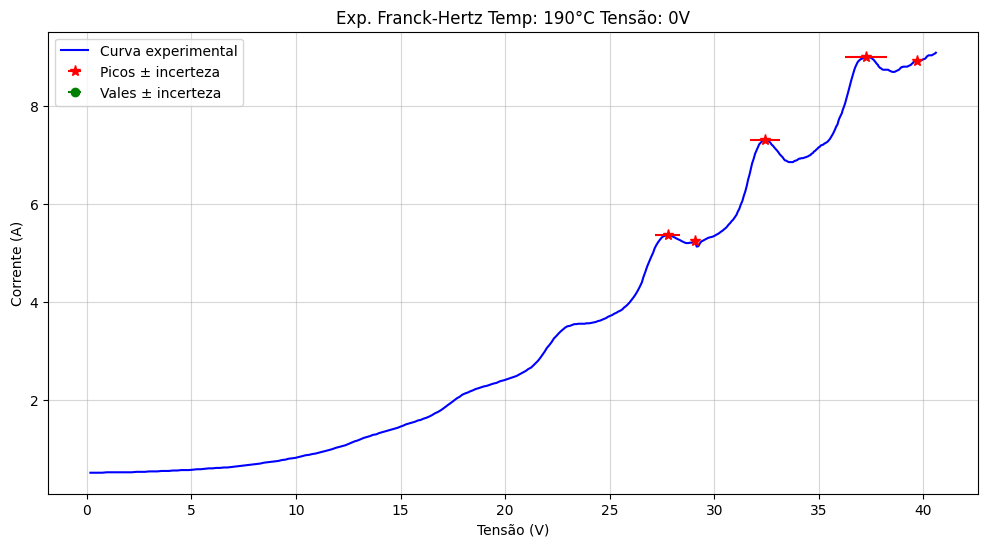

A diferença entre os picos 2 e 1 é de 1.32 V
A diferença entre os picos 3 e 2 é de 3.35 V
A diferença entre os picos 4 e 3 é de 4.80 V
A diferença entre os picos 5 e 4 é de 2.45 V


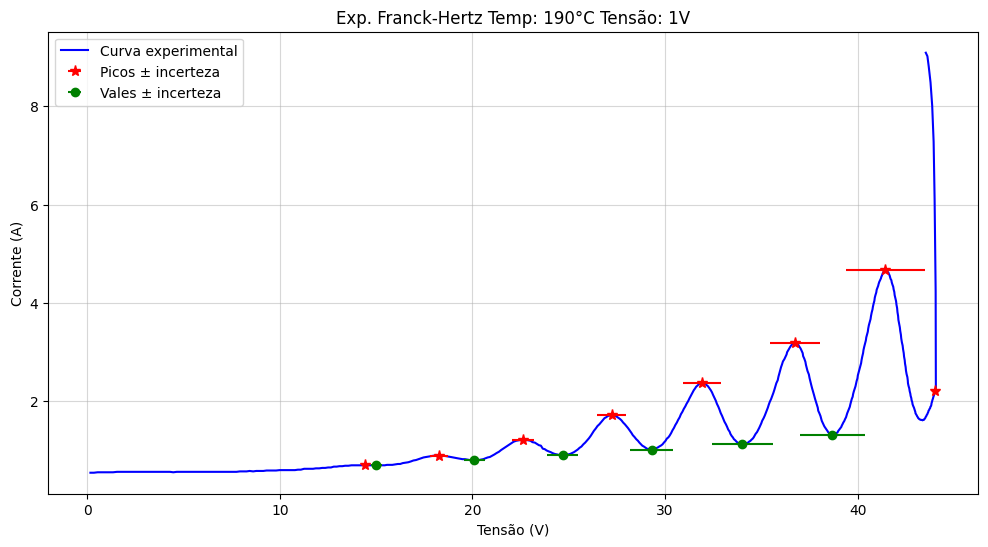

A diferença entre os picos 2 e 1 é de 3.82 V
A diferença entre os picos 3 e 2 é de 4.37 V
A diferença entre os picos 4 e 3 é de 4.61 V
A diferença entre os picos 5 e 4 é de 4.67 V
A diferença entre os picos 6 e 5 é de 4.86 V
A diferença entre os picos 7 e 6 é de 4.67 V
A diferença entre os picos 8 e 7 é de 2.58 V
A diferença entre os vales 2 e 1 é de 5.10 V
A diferença entre os vales 3 e 2 é de 4.58 V
A diferença entre os vales 4 e 3 é de 4.62 V
A diferença entre os vales 5 e 4 é de 4.71 V
A diferença entre os vales 6 e 5 é de 4.67 V


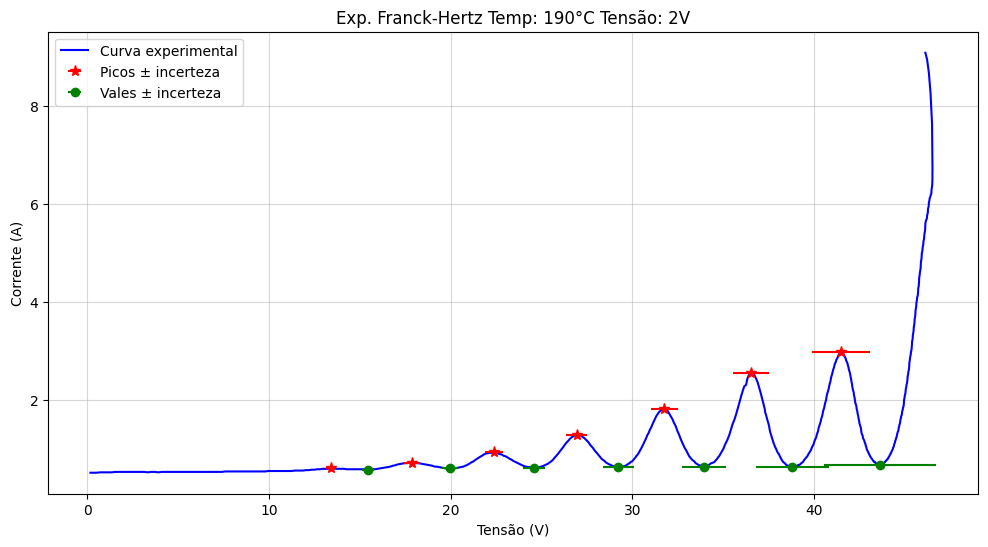

A diferença entre os picos 2 e 1 é de 4.46 V
A diferença entre os picos 3 e 2 é de 4.53 V
A diferença entre os picos 4 e 3 é de 4.56 V
A diferença entre os picos 5 e 4 é de 4.82 V
A diferença entre os picos 6 e 5 é de 4.80 V
A diferença entre os picos 7 e 6 é de 4.95 V
A diferença entre os vales 2 e 1 é de 4.53 V
A diferença entre os vales 3 e 2 é de 4.61 V
A diferença entre os vales 4 e 3 é de 4.65 V
A diferença entre os vales 5 e 4 é de 4.73 V
A diferença entre os vales 6 e 5 é de 4.86 V
A diferença entre os vales 7 e 6 é de 4.81 V


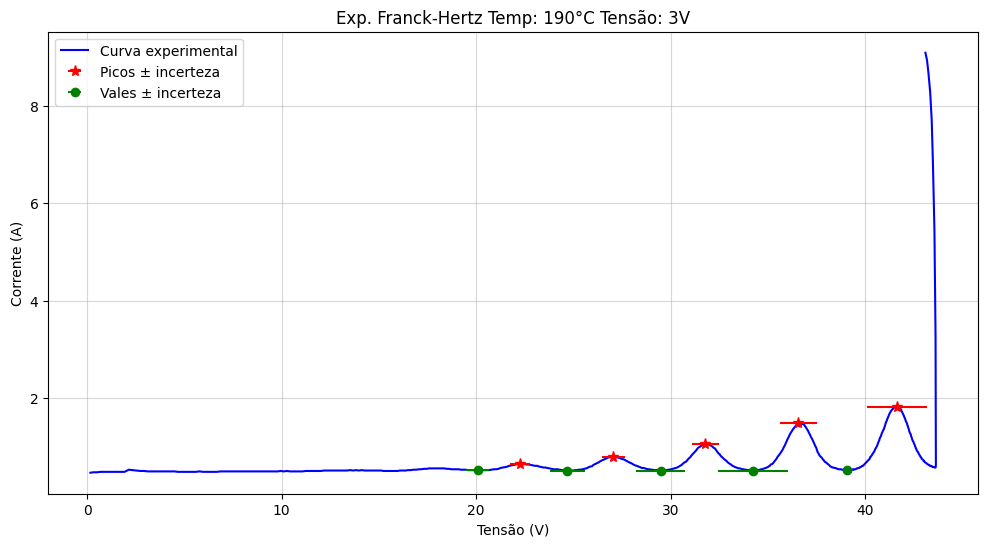

A diferença entre os picos 2 e 1 é de 4.80 V
A diferença entre os picos 3 e 2 é de 4.73 V
A diferença entre os picos 4 e 3 é de 4.77 V
A diferença entre os picos 5 e 4 é de 5.06 V
A diferença entre os vales 2 e 1 é de 4.61 V
A diferença entre os vales 3 e 2 é de 4.80 V
A diferença entre os vales 4 e 3 é de 4.76 V
A diferença entre os vales 5 e 4 é de 4.82 V


([np.float64(4.798000000000002),
  np.float64(4.727),
  np.float64(4.7719999999999985),
  np.float64(5.063000000000002)],
 [np.float64(4.609999999999999),
  np.float64(4.797000000000001),
  np.float64(4.758000000000003),
  np.float64(4.815999999999995)],
 array([0.50902632, 0.60983998, 0.71285721, 0.95959489, 1.53161204]),
 array([0.57360727, 0.90821151, 1.26193599, 1.8001354 , 0.15296194]))

In [4]:
# Caminho para o arquivo
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_0A_190,0.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_1V_189,5.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_2V_190,02.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_3V_190,3.txt'


analise(url1, 190, 0)
analise(url2, 190, 1,limite_inf_pico=10,limite_inf_vale=10,limite_sup_vale=40,limite_sup_pico=46)
analise(url3, 190, 2,limite_inf_pico=10,limite_inf_vale=10)
analise(url4, 190, 3,limite_inf_pico=17,limite_inf_vale=17,limite_sup_vale=39.2,altura_pico = 0.6,altura_vale =0.6)



In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_0V_161,2.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_0V_175,7.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_0V_178.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_0A_190,0.txt'

dados3D = []

analise(url1, 160, 0,plot=False)
analise(url2, 170, 0,plot=False)
analise(url3, 180, 0,plot=False)
analise(url4, 190, 0,plot=False)
grafico3D(sep=False, num_pontos=100)

In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_1V_160,5.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_1V_170,2.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_1V_180,8.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_1V_189,5.txt'

dados3D = []
analise(url1, 160, 0,plot=False)
analise(url2, 170, 0,plot=False)
analise(url3, 180, 0,plot=False)
analise(url4, 190, 0,plot=False)
grafico3D()


In [ ]:
url1 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_0V_161,2.txt'
url2 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_1V_160,5.txt'
url3 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_2V_158,7.txt'
url4 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/160_3V_160,5.txt'
url5 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_0V_175,7.txt'
url6 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_1V_170,2.txt'
url7 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_2V_168,0.txt'
url8 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/170_3V_170,4.txt'
url9 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_0V_178.txt'
url10 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_1V_180,8.txt'
url11 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_2V_182,0.txt'
url12 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/180_3V_180,0.txt'
url13 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_0A_190,0.txt'
url14 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_1V_189,5.txt'
url15 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_2V_190,02.txt'
url16 = '/content/drive/MyDrive/2025s2/F 740/Franck-Hertz/190_3V_190,3.txt'

# --- Temperatura 160°C ---
picos160_0, vales160_0, inc_p160_0, inc_v160_0 = analise(url1, 160, 0, plot=False, labels=False)
picos160_1, vales160_1, inc_p160_1, inc_v160_1 = analise(url2, 160, 1, limite_inf_vale=5, plot=False, labels=False)
picos160_2, vales160_2, inc_p160_2, inc_v160_2 = analise(url3, 160, 2, plot=False, labels=False)
picos160_3, vales160_3, inc_p160_3, inc_v160_3 = analise(url4, 160, 3, limite_inf_vale=5, plot=False, labels=False)

# --- Temperatura 170°C ---
picos170_0, vales170_0, inc_p170_0, inc_v170_0 = analise(url5, 170, 0, limite_inf_vale=5, plot=False, labels=False)
picos170_1, vales170_1, inc_p170_1, inc_v170_1 = analise(url6, 170, 1, limite_inf_vale=5, plot=False, labels=False)
picos170_2, vales170_2, inc_p170_2, inc_v170_2 = analise(url7, 170, 2, limite_inf_vale=5, plot=False, labels=False)
picos170_3, vales170_3, inc_p170_3, inc_v170_3 = analise(url8, 170, 3, limite_inf_vale=10, limite_sup_vale=25, plot=False, labels=False)

# --- Temperatura 180°C ---
picos180_0, vales180_0, inc_p180_0, inc_v180_0 = analise(url9, 180, 0, limite_inf_vale=5, plot=False, labels=False)
picos180_1, vales180_1, inc_p180_1, inc_v180_1 = analise(url10, 180, 1, limite_inf_vale=5, plot=False, labels=False)
picos180_2, vales180_2, inc_p180_2, inc_v180_2 = analise(url11, 180, 2, limite_inf_vale=5, limite_sup_vale=30, plot=False, labels=False)
picos180_3, vales180_3, inc_p180_3, inc_v180_3 = analise(url12, 180, 3, limite_inf_vale=12, limite_inf_pico=11, limite_sup_vale=25, plot=False, labels=False)

# --- Temperatura 190°C ---
# Não há picos/vales para V=0, então podemos usar np.nan
picos190_0, vales190_0, inc_p190_0, inc_v190_0 = np.nan, np.nan, np.nan, np.nan
picos190_1, vales190_1, inc_p190_1, inc_v190_1 = analise(url14, 190, 1, limite_inf_pico=10, limite_inf_vale=10, limite_sup_vale=40, limite_sup_pico=46, plot=False, labels=False)
picos190_2, vales190_2, inc_p190_2, inc_v190_2 = analise(url15, 190, 2, limite_inf_pico=10, limite_inf_vale=10, plot=False, labels=False)
picos190_3, vales190_3, inc_p190_3, inc_v190_3 = analise(url16, 190, 3, limite_inf_pico=17, limite_inf_vale=17, limite_sup_vale=39.2, altura_pico=0.6, altura_vale=0.6, plot=False, labels=False)


In [ ]:


plt.plot(picos160_0,marker='o',label="160C_0V")
plt.plot(picos170_0,marker='o',label="170C_0V")
plt.plot(picos180_0,marker='o',label="180C_0V")
plt.plot(picos190_0,marker='o',label="190C_0V")
plt.legend()
plt.show()

plt.plot(vales160_0,marker='o',label="160C_0V")
plt.plot(vales170_0,marker='o',label="170C_0V")
plt.plot(vales180_0,marker='o',label="180C_0V")
plt.plot(vales190_0,marker='o',label="190C_0V")

In [ ]:
plt.plot(picos160_1, marker='o',label="160C_1V")
plt.plot(picos170_1, marker='o',label="170C_1V")
plt.plot(picos180_1, marker='o',label="180C_1V")
plt.plot(picos190_1, marker='o',label="190C_1V")
plt.legend()
plt.show()

plt.plot(vales160_1, marker='o',label="160C_1V")
plt.plot(vales170_1, marker='o',label="170C_1V")
plt.plot(vales180_1, marker='o',label="180C_1V")
plt.plot(vales190_1, marker='o',label="190C_1V")
plt.legend()

In [ ]:
plt.plot(picos160_2, marker='o',label="160C_2V")
plt.plot(picos170_2, marker='o',label="170C_2V")
plt.plot(picos180_2, marker='o',label="180C_2V")
plt.plot(picos190_2, marker='o',label="190C_2V")
plt.legend()
plt.show()

plt.plot(vales160_2, marker='o',label="160C_2V")
plt.plot(vales170_2, marker='o',label="170C_2V")
plt.plot(vales180_2, marker='o',label="180C_2V")
plt.plot(vales190_2, marker='o',label="190C_2V")
plt.legend()


In [ ]:
plt.plot(picos160_3, marker='o',label="160C_3V")
plt.plot(picos170_3, marker='o',label="170C_3V")
plt.plot(picos180_3, marker='o',label="180C_3V")
plt.plot(picos190_3, marker='o',label="190C_3V")
plt.legend()
plt.show()

plt.plot(vales160_3, marker='o',label="160C_3V")
plt.plot(vales170_3, marker='o',label="170C_3V")
plt.plot(vales180_3, marker='o',label="180C_3V")
plt.plot(vales190_3, marker='o',label="190C_3V")
plt.legend()


In [ ]:
plt.plot(picos160_0,marker='o',label="160C_0V")
plt.plot(picos160_1,marker='o',label="160C_1V")
plt.plot(picos160_2,marker='o',label="160C_2V")
plt.plot(picos160_3,marker='o',label="160C_3V")
plt.legend()
plt.show()

plt.plot(vales160_0,marker='o',label="160C_0V")
plt.plot(vales160_1,marker='o',label="160C_1V")
plt.plot(vales160_2,marker='o',label="160C_2V")
plt.plot(vales160_3,marker='o',label="160C_3V")
plt.legend()

In [ ]:
plt.plot(picos170_0,marker='o',label="170C_0V")
plt.plot(picos170_1,marker='o',label="170C_1V")
plt.plot(picos170_2,marker='o',label="170C_2V")
plt.plot(picos170_3,marker='o',label="170C_3V")
plt.legend()

In [ ]:
plt.plot(picos180_0,marker='o',label="180C_0V")
plt.plot(picos180_1,marker='o',label="180C_1V")
plt.plot(picos180_2,marker='o',label="180C_2V")
plt.plot(picos180_3,marker='o',label="180C_3V")
plt.legend()

In [ ]:
plt.plot(picos190_0,marker='o',label="190C_0V")
plt.plot(picos190_1,marker='o',label="190C_1V")
plt.plot(picos190_2,marker='o',label="190C_2V")
plt.plot(picos190_3,marker='o',label="190C_3V")
plt.legend()

In [ ]:
print(mean(picos160_0))
print(mean(picos160_1))
print(mean(picos160_2))
print(mean(picos160_3))
print("----------------------")
print(mean(picos170_0))
print(mean(picos170_1))
print(mean(picos170_2))
print(mean(picos170_3))
print("----------------------")
print(mean(picos180_0))
print(mean(picos180_1))
print(mean(picos180_2))
print(mean(picos180_3))
print("----------------------")
print(mean(picos190_1))
print(mean(picos190_2))
print(mean(picos190_3))


In [ ]:
import numpy as np
import pandas as pd

# -----------------------------
# Função para montar tabelas
# -----------------------------
def construir_tabela_val_erro(valores_dict, incertezas_dict, tipo="picos", metodo_erro="mean"):
    """
    Constrói um DataFrame T×V com "valor ± erro".

    valor = média dos valores de cada T×V
    erro  = média OU RMS das incertezas individuais (escolhido em metodo_erro)

    metodo_erro:
        - "mean" → média simples das incertezas
        - "rms"  → raiz da média dos quadrados (mais físico)
    """
    tabela = []
    tensoes = [0, 1, 2, 3]

    for T in [160, 170, 180, 190]:
        linha = {'T': T}
        medias_linha = []
        erros_linha = []

        for V in tensoes:
            val = valores_dict[T][V]
            inc = incertezas_dict[T][V]

            if val is None or (isinstance(val, float) and np.isnan(val)) or len(val) == 0:
                linha[f'V={V}'] = np.nan
                continue

            # Média dos valores
            val_arr = np.array(val, dtype=float)
            media_val = np.nanmean(val_arr)

            # Erro: média ou RMS das incertezas
            if inc is not None and not (isinstance(inc, float) and np.isnan(inc)):
                inc_arr = np.array(inc, dtype=float)
                if metodo_erro == "rms":
                    erro_val = np.sqrt(np.nanmean(inc_arr**2))
                else:
                    erro_val = np.nanmean(inc_arr)
            else:
                erro_val = 0.0

            linha[f'V={V}'] = f"{media_val:.2f} ± {erro_val:.2f}"
            medias_linha.append(media_val)
            erros_linha.append(erro_val)

        # Média da linha (global por T)
        if len(medias_linha) > 0:
            media_linha = np.mean(medias_linha)
            if metodo_erro == "rms":
                erro_linha = np.sqrt(np.mean(np.array(erros_linha)**2))
            else:
                erro_linha = np.mean(erros_linha)
            linha[f'media_{tipo}'] = f"{media_linha:.2f} ± {erro_linha:.2f}"
        else:
            linha[f'media_{tipo}'] = np.nan

        tabela.append(linha)

    df = pd.DataFrame(tabela)

    # Linha média por coluna V
    media_col = {'T': 'Média V'}
    for V in tensoes:
        col_vals, col_errs = [], []
        for T in [160, 170, 180, 190]:
            val = valores_dict[T][V]
            inc = incertezas_dict[T][V]
            if val is None or (isinstance(val, float) and np.isnan(val)) or len(val) == 0:
                continue
            col_vals.append(np.nanmean(val))
            if inc is not None and not (isinstance(inc, float) and np.isnan(inc)):
                inc_arr = np.array(inc, dtype=float)
                if metodo_erro == "rms":
                    col_errs.append(np.sqrt(np.nanmean(inc_arr**2)))
                else:
                    col_errs.append(np.nanmean(inc_arr))
        if len(col_vals) > 0:
            media_val = np.mean(col_vals)
            erro_val = np.sqrt(np.mean(np.array(col_errs)**2)) if metodo_erro == "rms" else np.mean(col_errs)
            media_col[f'V={V}'] = f"{media_val:.2f} ± {erro_val:.2f}"
        else:
            media_col[f'V={V}'] = np.nan

    # Média global
    todas_vals, todas_errs = [], []
    for T in [160, 170, 180, 190]:
        for V in tensoes:
            val = valores_dict[T][V]
            inc = incertezas_dict[T][V]
            if val is None or (isinstance(val, float) and np.isnan(val)) or len(val) == 0:
                continue
            todas_vals.append(np.nanmean(val))
            if inc is not None and not (isinstance(inc, float) and np.isnan(inc)):
                inc_arr = np.array(inc, dtype=float)
                if metodo_erro == "rms":
                    todas_errs.append(np.sqrt(np.nanmean(inc_arr**2)))
                else:
                    todas_errs.append(np.nanmean(inc_arr))
    if len(todas_vals) > 0:
        media_global = np.mean(todas_vals)
        erro_global = np.sqrt(np.mean(np.array(todas_errs)**2)) if metodo_erro == "rms" else np.mean(todas_errs)
        media_col[f'media_{tipo}'] = f"{media_global:.2f} ± {erro_global:.2f}"
    else:
        media_col[f'media_{tipo}'] = np.nan

    df = pd.concat([df, pd.DataFrame([media_col])], ignore_index=True)
    return df

# -----------------------------
# Dicionários (exemplo, use seus picos/vales reais)
# -----------------------------
picos = {
    160: {0: picos160_0, 1: picos160_1, 2: picos160_2, 3: picos160_3},
    170: {0: picos170_0, 1: picos170_1, 2: picos170_2, 3: picos170_3},
    180: {0: picos180_0, 1: picos180_1, 2: picos180_2, 3: picos180_3},
    190: {0: None,       1: picos190_1, 2: picos190_2, 3: picos190_3}
}

vales = {
    160: {0: vales160_0, 1: vales160_1, 2: vales160_2, 3: vales160_3},
    170: {0: vales170_0, 1: vales170_1, 2: vales170_2, 3: vales170_3},
    180: {0: vales180_0, 1: vales180_1, 2: vales180_2, 3: vales180_3},
    190: {0: None,        1: vales190_1, 2: vales190_2, 3: vales190_3}
}

inc_p = {
    160: {0: inc_p160_0, 1: inc_p160_1, 2: inc_p160_2, 3: inc_p160_3},
    170: {0: inc_p170_0, 1: inc_p170_1, 2: inc_p170_2, 3: inc_p170_3},
    180: {0: inc_p180_0, 1: inc_p180_1, 2: inc_p180_2, 3: inc_p180_3},
    190: {0: None,        1: inc_p190_1, 2: inc_p190_2, 3: inc_p190_3}
}

inc_v = {
    160: {0: inc_v160_0, 1: inc_v160_1, 2: inc_v160_2, 3: inc_v160_3},
    170: {0: inc_v170_0, 1: inc_v170_1, 2: inc_v170_2, 3: inc_v170_3},
    180: {0: inc_v180_0, 1: inc_v180_1, 2: inc_v180_2, 3: inc_v180_3},
    190: {0: None,        1: inc_v190_1, 2: inc_v190_2, 3: inc_v190_3}
}

# -----------------------------
# Construir tabelas finais
# -----------------------------
df_picos = construir_tabela_val_erro(picos, inc_p, tipo="picos", metodo_erro="rms")
df_vales = construir_tabela_val_erro(vales, inc_v, tipo="vales", metodo_erro="rms")

print("\nTabela de Picos:")
print(df_picos)

print("\nTabela de Vales:")
print(df_vales)


In [ ]:
df_picos


In [ ]:
df_vales

In [ ]:
df_vales = construir_tabela_val_erro(vales, tipo="vales")
df_vales

In [ ]:
analise(url10,170,2)


In [ ]:
!apt update
!apt install -y ffmpeg texlive texlive-latex-extra texlive-fonts-recommended dvipng cm-super
!pip install manim

In [ ]:
e = 1.602e-19        # C
c = 3e8              # m/s
delta_U = 4.85       # V
lambda_hg = 254e-9   # m
h_real = 6.626e-34


h_val = e*delta_U*lambda_hg/c
print(h_val)
diff_percent = abs(h_val - h_real)/h_real * 100
print(diff_percent)